# Audit: kenapa hasil skripsi tidak bertahan saat diuji ulang

Notebook ini memuat analisis pendukung untuk halaman studi kasus. Tidak butuh TensorFlow, dan bisa dijalankan di laptop biasa.

Isinya:
1. Seberapa bisa ditebak inflasi bulanan? (autokorelasi)
2. Apakah model linear sederhana bisa mengalahkan rata-rata 12 bulan?
3. Perubahan gejolak inflasi antar-era
4. Rentang UMR di data latih vs data uji
5. Ukuran model vs jumlah data latih
6. Model datar vs MSE (memakai hasil `01_eksperimen_lstm.ipynb`)

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import RidgeCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

ROOT = next(p for p in [Path(".."), Path(".")] if (p / "data").exists())
df = pd.read_csv(ROOT / "data" / "inflasi_umr_5kota_2000_2025.csv")
df["Tanggal"] = pd.to_datetime(df["Tanggal"], format="%m/%d/%Y")
df = df.sort_values(["Kota", "Tanggal"]).reset_index(drop=True)

CITIES = ["KOTA MEDAN", "DKI JAKARTA", "KOTA BANDUNG", "KOTA SURABAYA", "KOTA MAKASSAR"]
N = 312
TRAIN_END = int(N * 0.8)   # 249 -> uji mulai Okt 2020, sama dengan skripsi
series = {c: df[df.Kota == c].reset_index(drop=True) for c in CITIES}
print("Uji:", series[CITIES[0]].Tanggal[TRAIN_END].strftime("%b %Y"), "–", series[CITIES[0]].Tanggal.iloc[-1].strftime("%b %Y"))

Uji: Oct 2020 – Dec 2025


## 1. Seberapa bisa ditebak inflasi bulanan?

Autokorelasi mengukur seberapa mirip inflasi suatu bulan dengan bulan sebelumnya (lag 1) atau bulan yang sama tahun lalu (lag 12). Nilai mendekati 0 berarti masa lalu hampir tidak memberi petunjuk. Dihitung hanya pada data latih.

In [2]:
acf = pd.DataFrame({c: {"lag 1": series[c].Inflasi[:TRAIN_END].autocorr(1),
                        "lag 12": series[c].Inflasi[:TRAIN_END].autocorr(12)} for c in CITIES}).T.round(2)
acf

,lag 1,lag 12
KOTA MEDAN,0.17,0.14
DKI JAKARTA,0.20,0.10
KOTA BANDUNG,0.30,0.09
KOTA SURABAYA,0.20,0.18
KOTA MAKASSAR,0.08,0.29


## 2. Pembanding: model linear dan rata-rata musiman

Kalau ada pola yang bisa dipelajari, model linear sederhana (Ridge dengan 12 lag + efek bulan) seharusnya mengalahkan rata-rata 12 bulan terakhir. Saya juga menambahkan rata-rata bulan yang sama dalam 5 tahun terakhir.

In [3]:
rows = []
for c in CITIES:
    g = series[c]; y = g.Inflasi.values; n = len(y); yt = y[TRAIN_END:]
    X = np.array([np.r_[y[i-12:i], np.eye(12)[g.Tanggal[i].month - 1]] for i in range(12, n)]); Y = y[12:]
    ridge = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 30))).fit(X[:TRAIN_END-12], Y[:TRAIN_END-12])
    preds = {
        "Rata-rata 12 bulan": np.array([y[i-12:i].mean() for i in range(TRAIN_END, n)]),
        "Rata-rata musiman 5 tahun": np.array([np.mean([y[i-12*k] for k in range(1, 6)]) for i in range(TRAIN_END, n)]),
        "Ridge (12 lag + bulan)": ridge.predict(X[TRAIN_END-12:]),
    }
    rows.append({"Kota": c, **{k: np.mean((yt - p) ** 2) for k, p in preds.items()}})
bench = pd.DataFrame(rows).set_index("Kota").round(4)
bench["Ridge kalah dari rata-rata 12 bln?"] = bench["Ridge (12 lag + bulan)"] > bench["Rata-rata 12 bulan"]
bench

,Rata-rata 12 bulan,Rata-rata musiman 5 tahun,Ridge (12 lag + bulan),Ridge kalah dari rata-rata 12 bln?
Kota,,,,
KOTA MEDAN,0.3020,0.2963,0.3412,True
DKI JAKARTA,0.2019,0.1790,0.2535,True
KOTA BANDUNG,0.2727,0.2589,0.2891,True
KOTA SURABAYA,0.1525,0.1581,0.1799,True
KOTA MAKASSAR,0.3088,0.2624,0.3317,True


## 3. Gejolak inflasi antar-era

Simpangan baku inflasi bulanan per periode. Model dilatih pada data yang didominasi gejolak 2000–2009 (termasuk kenaikan BBM Okt 2005), lalu diuji pada periode yang jauh lebih tenang.

In [4]:
sd = pd.DataFrame({c: {"2000–2009": series[c].Inflasi[:120].std(),
                       "2010–Sep 2020": series[c].Inflasi[120:TRAIN_END].std(),
                       "Uji (Okt 2020–2025)": series[c].Inflasi[TRAIN_END:].std(),
                       "Maks data latih": series[c].Inflasi[:TRAIN_END].max()} for c in CITIES}).T.round(2)
sd["Rasio 2000–09 / uji"] = (sd["2000–2009"] / sd["Uji (Okt 2020–2025)"]).round(1)
sd

,2000–2009,2010–Sep 2020,Uji (Okt 2020–2025),Maks data latih,Rasio 2000–09 / uji
KOTA MEDAN,1.41,0.78,0.52,11.89,2.7
DKI JAKARTA,0.87,0.46,0.43,7.93,2.0
KOTA BANDUNG,1.00,0.49,0.50,8.22,2.0
KOTA SURABAYA,0.91,0.48,0.38,7.71,2.4
KOTA MAKASSAR,1.20,0.63,0.54,9.44,2.2


## 4. Rentang UMR: data latih vs data uji

Scaler di-fit pada data latih. Kalau nilai di data uji berada di luar rentang itu, model harus menebak di luar pengalamannya.

In [5]:
rows = []
for c in CITIES:
    g = series[c]
    lvl = g.UMR.values.reshape(-1, 1).astype(float)
    z = StandardScaler().fit(lvl[:TRAIN_END]).transform(lvl).ravel()
    growth = (g.UMR / g.UMR.shift(12) - 1) * 100
    rows.append({"Kota": c,
                 "UMR level z: maks latih": z[:TRAIN_END].max(), "UMR level z: uji min": z[TRAIN_END:].min(), "UMR level z: uji maks": z[TRAIN_END:].max(),
                 "Kenaikan UMR: min latih (%)": growth[12:TRAIN_END].min(), "Kenaikan UMR: min uji (%)": growth[TRAIN_END:].min()})
pd.DataFrame(rows).set_index("Kota").round(2)

,UMR level z: maks latih,UMR level z: uji min,UMR level z: uji maks,Kenaikan UMR: min latih (%),Kenaikan UMR: min uji (%)
Kota,,,,,
KOTA MEDAN,2.16,2.16,2.92,4.89,0.00
DKI JAKARTA,2.11,2.11,3.03,3.04,3.27
KOTA BANDUNG,2.11,2.11,2.95,8.14,0.87
KOTA SURABAYA,2.11,2.11,2.72,7.71,1.74
KOTA MAKASSAR,2.18,2.18,2.91,8.21,0.22


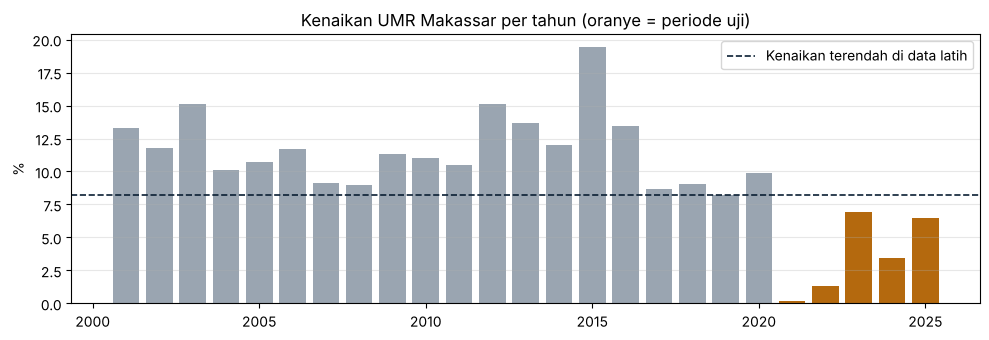

In [6]:
g = series["KOTA MAKASSAR"]; growth = (g.UMR / g.UMR.shift(12) - 1) * 100
jan = g.Tanggal.dt.month == 1
yrs, vals = g.Tanggal[jan & (g.Tanggal.dt.year >= 2001)].dt.year, growth[jan & (g.Tanggal.dt.year >= 2001)]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(yrs, vals, color=["#B4690E" if y >= 2021 else "#9AA5B1" for y in yrs])
ax.axhline(growth[12:TRAIN_END].min(), ls="--", color="#0B1F33", lw=1.2, label="Kenaikan terendah di data latih")
ax.set_title("Kenaikan UMR Makassar per tahun (oranye = periode uji)"); ax.set_ylabel("%"); ax.legend(); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()

## 5. Ukuran model vs jumlah data latih

In [7]:
def lstm_params(n_in, units):
    return 4 * (units * (n_in + units) + units)

leipary = lstm_params(1, 256) + lstm_params(256, 128) + lstm_params(128, 64) + (64 + 1)
windows = TRAIN_END - 12
print(f"Parameter LSTM Leipary (256-128-64, 1 fitur): {leipary:,}")
print(f"Contoh latih per kota (lag 12): {windows}")
print(f"Parameter per contoh latih: {leipary / windows:,.0f}")

Parameter LSTM Leipary (256-128-64, 1 fitur): 510,785
Contoh latih per kota (lag 12): 237
Parameter per contoh latih: 2,155


## 6. Model datar vs MSE

Memakai hasil `01_eksperimen_lstm.ipynb` (folder `outputs/`). Rasio variasi = simpangan baku prediksi / simpangan baku aktual. Nilai mendekati 0 berarti prediksinya hampir datar.

In [8]:
m = pd.read_csv(ROOT / "outputs" / "metrics_all.csv")
s1 = m[m.Skenario == "S1"]
view = s1.pivot(index="Kota", columns="Model", values="MSE").round(4).join(
       s1.pivot(index="Kota", columns="Model", values="rasio_variasi").round(2), rsuffix=" · rasio variasi")
lowest = m.loc[m.groupby("Kota").MSE.idxmin(), ["Kota", "Model", "MSE", "rasio_variasi"]].set_index("Kota").round(4)
view

Model,"Artikel 1 (Muhajir dkk., 2024)","Artikel 2 (Masipupu dkk., 2025)","Artikel 3 (Leipary & Setiawan, 2025)","Artikel 1 (Muhajir dkk., 2024) · rasio variasi","Artikel 2 (Masipupu dkk., 2025) · rasio variasi","Artikel 3 (Leipary & Setiawan, 2025) · rasio variasi"
Kota,,,,,,
DKI JAKARTA,0.1931,0.2090,0.1941,0.04,0.26,0.23
KOTA BANDUNG,0.2464,0.2657,0.5616,0.05,0.26,0.87
KOTA MAKASSAR,0.2867,0.2935,0.3763,0.02,0.16,0.50
KOTA MEDAN,0.2794,0.2871,0.5417,0.03,0.15,0.77
KOTA SURABAYA,0.1423,0.1444,0.4083,0.04,0.24,1.34


Model dengan MSE terkecil di tiap kota, dari semua skenario dan pembanding. Perhatikan rasio variasinya:

In [9]:
lowest

,Model,MSE,rasio_variasi
Kota,,,
DKI JAKARTA,Baseline + UMR (level),0.1831,0.0666
KOTA BANDUNG,"Artikel 1 (Muhajir dkk., 2024)",0.2464,0.0505
KOTA MAKASSAR,Baseline + UMR (level),0.2838,0.2615
KOTA MEDAN,"Artikel 1 (Muhajir dkk., 2024)",0.2794,0.0328
KOTA SURABAYA,"Artikel 1 (Muhajir dkk., 2024)",0.1423,0.0384


## Kesimpulan

- Inflasi bulanan hanya sedikit berkorelasi dengan masa lalunya, sehingga model linear pun kalah dari rata-rata 12 bulan.
- Data latih didominasi era yang jauh lebih bergejolak daripada periode uji.
- UMR level di periode uji sama dengan atau di atas nilai tertinggi data latih, dan kenaikan UMR saat pandemi jauh di bawah kenaikan terendah di data latih.
- Model Leipary punya ribuan parameter untuk setiap contoh latih.
- Di 4 dari 5 kota, model dengan MSE terkecil adalah model yang hampir datar (rasio variasi ≤ 0,07). MSE saja tidak cukup untuk memilih model.